# Regresion logistica para predicciones bancarias

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("../datasets/bank/bank.csv", sep=";")

In [4]:
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,...,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,...,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,...,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


In [5]:
data.shape

(4119, 21)

In [6]:
data.columns.values

array(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'], dtype=object)

In [7]:
data["y"] = (data["y"] == "yes").astype(int)

In [8]:
data.tail()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
4114,30,admin.,married,basic.6y,no,yes,yes,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.958,5228.1,0
4115,39,admin.,married,high.school,no,yes,no,telephone,jul,fri,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.959,5228.1,0
4116,27,student,single,high.school,no,no,no,cellular,may,mon,...,2,999,1,failure,-1.8,92.893,-46.2,1.354,5099.1,0
4117,58,admin.,married,high.school,no,no,no,cellular,aug,fri,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.966,5228.1,0
4118,34,management,single,high.school,no,yes,no,cellular,nov,wed,...,1,999,0,nonexistent,-0.1,93.200,-42.0,4.120,5195.8,0


In [9]:
data["education"].unique()

array(['basic.9y', 'high.school', 'university.degree',
       'professional.course', 'basic.6y', 'basic.4y', 'unknown',
       'illiterate'], dtype=object)

In [10]:
data["education"] = np.where(data["education"] == "basic.4y", "Basic", data["education"])
data["education"] = np.where(data["education"] == "basic.6y", "Basic", data["education"])
data["education"] = np.where(data["education"] == "basic.9y", "Basic", data["education"])

data["education"] = np.where(data["education"] == "high.school", "High School", data["education"])
data["education"] = np.where(data["education"] == "professional.course", "Professional Course", data["education"])
data["education"] = np.where(data["education"] == "university.degree", "University Degree", data["education"])

data["education"] = np.where(data["education"] == "illiterate", "Illiterate", data["education"])
data["education"] = np.where(data["education"] == "unknown", "Unknown", data["education"])

In [11]:
data["education"].unique()

array(['Basic', 'High School', 'University Degree', 'Professional Course',
       'Unknown', 'Illiterate'], dtype=object)

In [12]:
data["y"].value_counts()

y
0    3668
1     451
Name: count, dtype: int64

In [13]:
data.groupby("y").mean(numeric_only=True)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
y,,,,,,,,,,
0,39.895311,219.40976,2.605780,982.763086,0.141767,0.240185,93.599677,-40.586723,3.802826,5175.502072
1,41.889135,560.78714,1.980044,778.722838,0.585366,-1.177384,93.417268,-39.786475,2.145448,5093.118625


In [14]:
data.groupby("education").mean(numeric_only=True)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
education,,,,,,,,,,,
Basic,42.337124,253.898457,2.429732,978.815597,0.149472,0.237368,93.658600,-41.120552,3.775701,5174.133144,0.079610
High School,38.097720,258.534202,2.630836,958.022801,0.206298,-0.002497,93.564314,-40.995765,3.511732,5163.212595,0.105320
Illiterate,42.000000,146.000000,4.000000,999.000000,0.000000,-2.900000,92.201000,-31.400000,0.834000,5076.200000,0.000000
Professional Course,40.207477,278.816822,2.512150,958.211215,0.194393,0.163925,93.599630,-40.127664,3.701426,5167.595140,0.121495
University Degree,39.017405,247.707278,2.583070,947.900316,0.207278,-0.009731,93.499109,-39.830063,3.547132,5163.023180,0.130538
Unknown,42.826347,267.281437,2.538922,939.700599,0.263473,-0.074251,93.637455,-39.487425,3.410174,5151.260479,0.155689


Text(0, 0.5, 'Frecuencia de compra del producto')

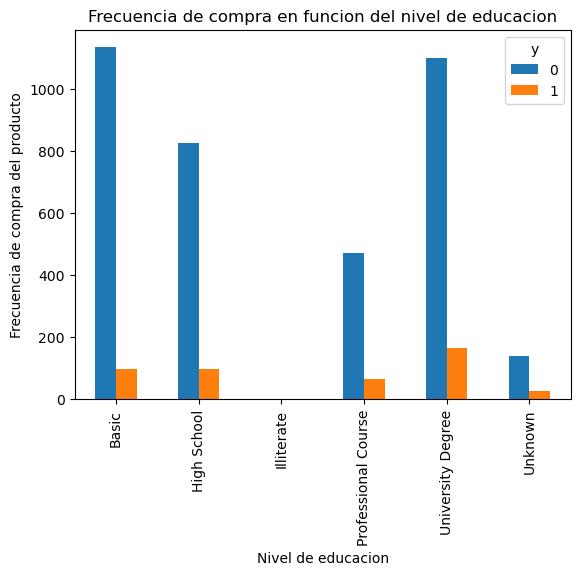

In [15]:
%matplotlib inline
pd.crosstab(data.education, data.y).plot(kind="bar")
plt.title("Frecuencia de compra en funcion del nivel de educacion")
plt.xlabel("Nivel de educacion")
plt.ylabel("Frecuencia de compra del producto")

Text(0, 0.5, 'Proporcion de clientes')

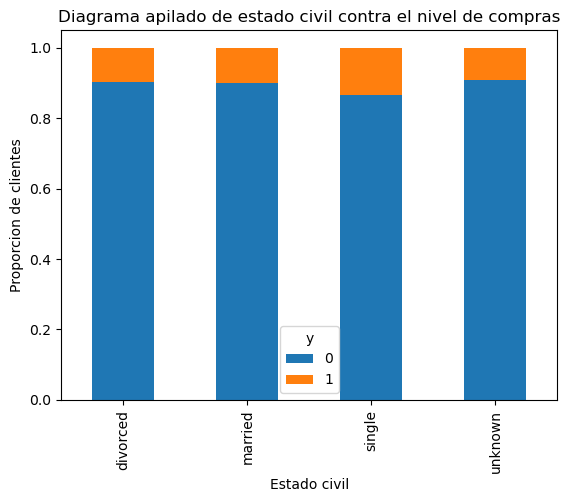

In [16]:
table = pd.crosstab(data.marital, data.y)
table.div(table.sum(1).astype(float), axis = 0 ).plot(kind="bar", stacked=True)
plt.title("Diagrama apilado de estado civil contra el nivel de compras")
plt.xlabel("Estado civil")
plt.ylabel("Proporcion de clientes")

Text(0, 0.5, 'Frecuencia de compra del producto')

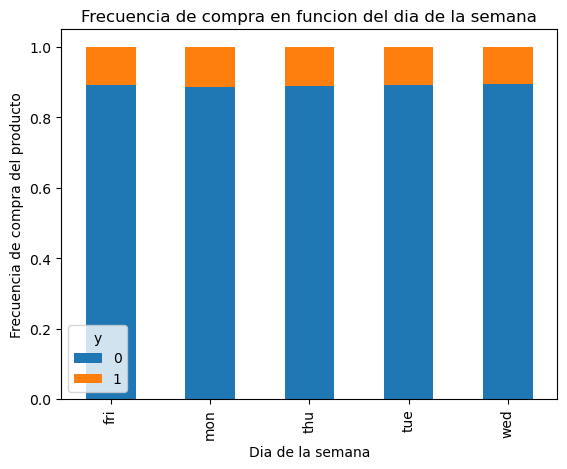

In [17]:
%matplotlib inline
table = pd.crosstab(data.day_of_week, data.y)
table.div(table.sum(1).astype(float), axis = 0).plot(kind="bar", stacked=True)
plt.title("Frecuencia de compra en funcion del dia de la semana")
plt.xlabel("Dia de la semana")
plt.ylabel("Frecuencia de compra del producto")

Text(0, 0.5, 'Frecuencia de compra del producto')

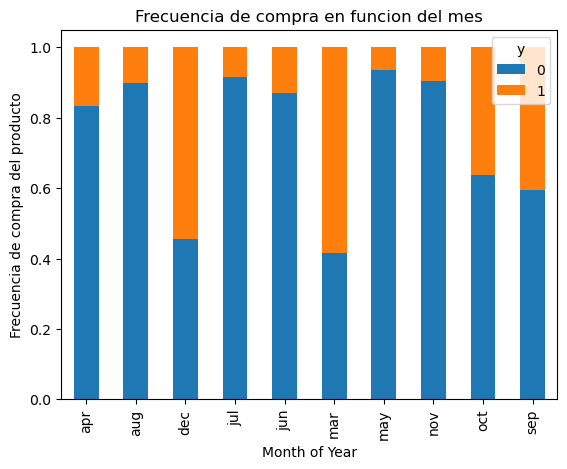

In [18]:
%matplotlib inline
table = pd.crosstab(data.month, data.y)
table.div(table.sum(1).astype(float), axis = 0).plot(kind="bar", stacked=True)
plt.title("Frecuencia de compra en funcion del mes")
plt.xlabel("Month of Year")
plt.ylabel("Frecuencia de compra del producto")

Text(0, 0.5, 'Frecuencia de compra del producto')

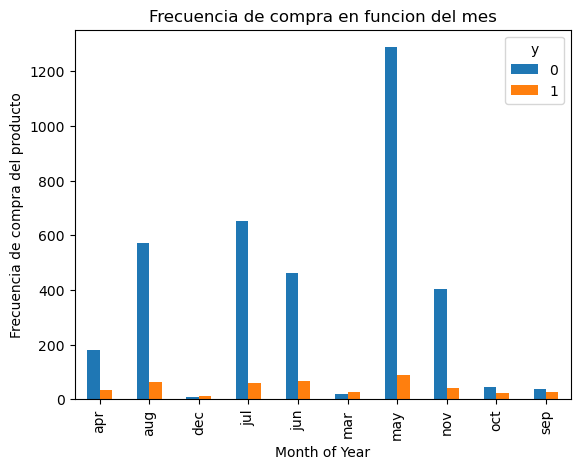

In [19]:
%matplotlib inline
table = pd.crosstab(data.month, data.y)
table.plot(kind="bar", stacked=False)
plt.title("Frecuencia de compra en funcion del mes")
plt.xlabel("Month of Year")
plt.ylabel("Frecuencia de compra del producto")

Text(0, 0.5, 'Cliente')

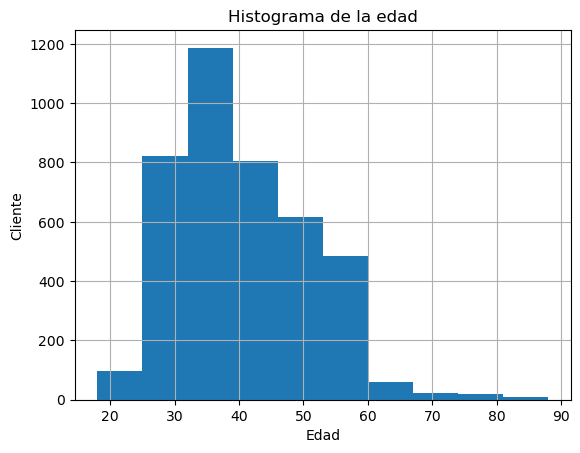

In [20]:
%matplotlib inline
data.age.hist()
plt.title("Histograma de la edad")
plt.xlabel("Edad")
plt.ylabel("Cliente")

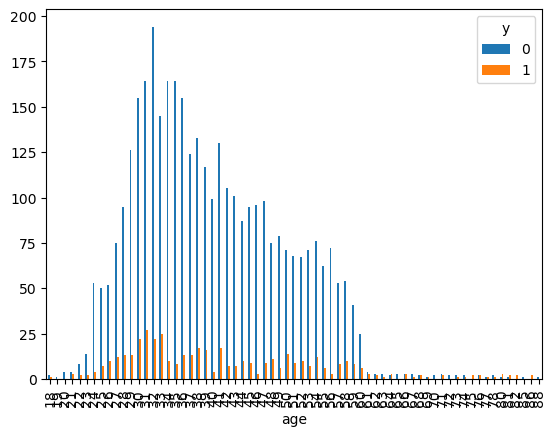

In [21]:
table = pd.crosstab(data.age, data.y).plot(kind="bar")

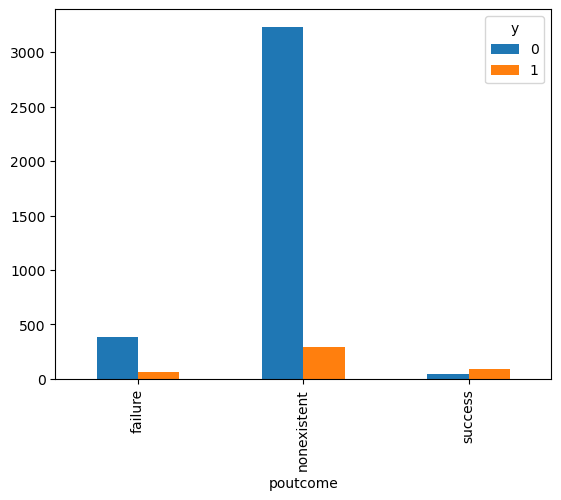

In [22]:
table = pd.crosstab(data.poutcome, data.y).plot(kind="bar")

### Conversion de las variables categoricas a dummies

In [23]:
categories = ["job", "marital", "education", "housing", "loan", "contact", 
              "month", "day_of_week", "poutcome"]
for category in categories:
    cat_list = "cat"+ "_"+category
    cat_dummies = pd.get_dummies(data[category], prefix=category)
    data_new = data.join(cat_dummies)
    data = data_new

In [24]:
data_vars = data.columns.values.tolist()

In [25]:
to_keep = [v for v in data_vars if v not in categories]
to_keep = [v for v in to_keep if v not in ["default"]]

In [26]:
bank_data = data[to_keep]
bank_data.columns.values

array(['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate',
       'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y',
       'job_admin.', 'job_blue-collar', 'job_entrepreneur',
       'job_housemaid', 'job_management', 'job_retired',
       'job_self-employed', 'job_services', 'job_student',
       'job_technician', 'job_unemployed', 'job_unknown',
       'marital_divorced', 'marital_married', 'marital_single',
       'marital_unknown', 'education_Basic', 'education_High School',
       'education_Illiterate', 'education_Professional Course',
       'education_University Degree', 'education_Unknown', 'housing_no',
       'housing_unknown', 'housing_yes', 'loan_no', 'loan_unknown',
       'loan_yes', 'contact_cellular', 'contact_telephone', 'month_apr',
       'month_aug', 'month_dec', 'month_jul', 'month_jun', 'month_mar',
       'month_may', 'month_nov', 'month_oct', 'month_sep',
       'day_of_week_fri', 'day_of_week_mon', 'day_of_week_thu',
       'd

In [27]:
bank_data_vars = bank_data.columns.values.tolist()
Y = ['y']
X = [v for v in bank_data_vars if v not in Y]

### Selección de rasgos para el modelo

In [28]:
n = 12

In [29]:
from sklearn import datasets
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

In [30]:
lr = LogisticRegression(solver='lbfgs',class_weight='balanced', max_iter=10000)

In [31]:
rfe = RFE(lr, n_features_to_select=12)
rfe = rfe.fit(bank_data[X], bank_data[Y].values.ravel())

C:\Users\progr\anaconda3\envs\ml-curso\lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 10000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=10000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [32]:
print(rfe.support_)

[False False False False False  True  True False False False False False
 False False False False  True False False False False False False False
 False  True False False False False False False False False False False
  True False  True False  True False  True False False  True  True  True
 False False False False False False False False False  True]


In [33]:
print(rfe.ranking_)

[39 46 26 47 15  1  1 31  3 43  7 37 21 27 16  4  1 45 30  6 13 28 22 32
 36  1 42 17  8 23 35 24 19 14 41 25  1 40  1  9  1 33  1 11  2  1  1  1
 10 12 44 38 29 34 18  5 20  1]


In [34]:
z=zip(bank_data_vars,rfe.support_, rfe.ranking_)

In [35]:
list(z)

[('age', np.False_, np.int64(39)),
 ('duration', np.False_, np.int64(46)),
 ('campaign', np.False_, np.int64(26)),
 ('pdays', np.False_, np.int64(47)),
 ('previous', np.False_, np.int64(15)),
 ('emp.var.rate', np.True_, np.int64(1)),
 ('cons.price.idx', np.True_, np.int64(1)),
 ('cons.conf.idx', np.False_, np.int64(31)),
 ('euribor3m', np.False_, np.int64(3)),
 ('nr.employed', np.False_, np.int64(43)),
 ('y', np.False_, np.int64(7)),
 ('job_admin.', np.False_, np.int64(37)),
 ('job_blue-collar', np.False_, np.int64(21)),
 ('job_entrepreneur', np.False_, np.int64(27)),
 ('job_housemaid', np.False_, np.int64(16)),
 ('job_management', np.False_, np.int64(4)),
 ('job_retired', np.True_, np.int64(1)),
 ('job_self-employed', np.False_, np.int64(45)),
 ('job_services', np.False_, np.int64(30)),
 ('job_student', np.False_, np.int64(6)),
 ('job_technician', np.False_, np.int64(13)),
 ('job_unemployed', np.False_, np.int64(28)),
 ('job_unknown', np.False_, np.int64(22)),
 ('marital_divorced', np

In [36]:
cols = ["previous", "euribor3m", "job_blue-collar", "job_retired", "month_aug", "month_dec", 
        "month_jul", "month_jun", "month_mar", "month_nov", "day_of_week_wed", "poutcome_nonexistent"]

In [37]:
X = bank_data[cols]
Y = bank_data["y"]

### Implementar del modelo en Python con statsmodel.api

In [38]:
import statsmodels.api as sm

In [39]:
logit_model = sm.Logit(Y,X)

In [40]:
result = logit_model.fit()

Optimization terminated successfully.
         Current function value: 0.291770
         Iterations 7


In [41]:
result.summary2()

<class 'statsmodels.iolib.summary2.Summary'>
"""
                           Results: Logit
=====================================================================
Model:                Logit             Method:            MLE       
Dependent Variable:   y                 Pseudo R-squared:  0.155     
Date:                 2026-10-06 11:30  AIC:               2427.6025 
No. Observations:     4119              BIC:               2503.4828 
Df Model:             11                Log-Likelihood:    -1201.8   
Df Residuals:         4107              LL-Null:           -1422.9   
Converged:            1.0000            LLR p-value:       6.4492e-88
No. Iterations:       7.0000            Scale:             1.0000    
---------------------------------------------------------------------
                      Coef.  Std.Err.    z     P>|z|   [0.025  0.975]
---------------------------------------------------------------------
previous             -0.1229   0.0700  -1.7545 0.0793 -0.2601  0.0144
euribor3m            -0.6049   0.0383 -15.7882 0.0000 -0.6800 -0.5298
job_blue-collar      -0.5032   0.1519  -3.3136 0.0009 -0.8009 -0.2056
job_retired           0.2235   0.2191   1.0205 0.3075 -0.2058  0.6529
month_aug             0.6048   0.1759   3.4374 0.0006  0.2600  0.9497
month_dec             1.1358   0.4493   2.5281 0.0115  0.2552  2.0163
month_jul             1.0327   0.1910   5.4071 0.0000  0.6584  1.4070
month_jun             1.0775   0.1752   6.1493 0.0000  0.7341  1.4210
month_mar             1.6448   0.3139   5.2407 0.0000  1.0297  2.2600
month_nov             0.3828   0.1950   1.9634 0.0496  0.0007  0.7649
day_of_week_wed      -0.0649   0.1391  -0.4665 0.6409 -0.3375  0.2077
poutcome_nonexistent -0.7753   0.1221  -6.3492 0.0000 -1.0147 -0.5360
=====================================================================

"""

### Implementacion del modelo en Python con scikit-learn

In [42]:
from sklearn import linear_model

In [43]:
logit_model = linear_model.LogisticRegression()
logit_model.fit(X,Y)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [44]:
logit_model.score(X,Y)

0.8958485069191552

In [45]:
1-Y.mean()

np.float64(0.8905074047098811)

In [46]:
pd.DataFrame(list(zip(X.columns, np.transpose(logit_model.coef_))))

,0,1
0,previous,[0.536202693170315]
1,euribor3m,[-0.5444516683502801]
2,job_blue-collar,[-0.35341869362366374]
3,job_retired,[0.3663591066695689]
4,month_aug,[0.6288946510758585]
5,month_dec,[1.1922909531378654]
6,month_jul,[0.9588337130230462]
7,month_jun,[1.054642751249518]
8,month_mar,[1.6434179667941984]
9,month_nov,[0.45509215599989233]


### Validacion del modelo logistico

In [47]:
from sklearn.model_selection import train_test_split

In [48]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size = 0.3, random_state=0)

In [49]:
lm = linear_model.LogisticRegression()
lm.fit(X_train, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [50]:
from IPython.display import display, Math, Latex

In [51]:
display(Math(r'Y_P=\begin{cases}0& si\ p\leq0.5\\1&si\ p>0.5\end{cases}'))

<IPython.core.display.Math object>

In [52]:
probs = lm.predict_proba(X_test)

In [53]:
probs

array([[0.95412144, 0.04587856],
       [0.83899096, 0.16100904],
       [0.93217587, 0.06782413],
       ...,
       [0.65014498, 0.34985502],
       [0.9738304 , 0.0261696 ],
       [0.57625226, 0.42374774]], shape=(1236, 2))

In [54]:
prediction = lm.predict(X_test)

In [55]:
prediction

array([0, 0, 0, ..., 0, 0, 0], shape=(1236,))

In [56]:
display(Math(r'\varepsilon\in (0,1), Y_p=\begin{cases}0& si\ p\leq \varepsilon\\1&si\ p >\varepsilon\end{cases}'))

<IPython.core.display.Math object>

In [57]:
prob = probs[:,1]
prob_df = pd.DataFrame(prob)
threshold = 0.1
prob_df["prediction"] = np.where(prob_df[0] > threshold, 1, 0)
prob_df.head()

,0,prediction
0,0.045879,0
1,0.161009,1
2,0.067824,0
3,0.062163,0
4,0.042281,0


In [58]:
pd.crosstab(prob_df.prediction, columns="count")

col_0,count
prediction,
0,846
1,390


In [59]:
390/len(prob_df)*100

31.55339805825243

In [60]:
threshold = 0.15
prob_df["prediction"] = np.where(prob_df[0] > threshold, 1, 0)
pd.crosstab(prob_df.prediction, columns="count")

col_0,count
prediction,
0,915
1,321


In [61]:
321/len(prob_df)*100

25.970873786407765

In [62]:
threshold = 0.05
prob_df["prediction"] = np.where(prob_df[0] > threshold, 1, 0)
pd.crosstab(prob_df.prediction, columns="count")

col_0,count
prediction,
0,504
1,732


In [63]:
732/len(prob_df)*100

59.22330097087378

In [64]:
from sklearn import metrics

In [65]:
metrics.accuracy_score(Y_test, prediction)

0.901294498381877

### Validacion cruzada

In [66]:
from sklearn.model_selection import cross_val_score

In [67]:
scores = cross_val_score(linear_model.LogisticRegression(), X, Y, scoring="accuracy", cv=10)

In [68]:
scores

array([0.90533981, 0.88834951, 0.90533981, 0.89563107, 0.90048544,
       0.8907767 , 0.88349515, 0.89320388, 0.89320388, 0.88807786])

In [69]:
scores.mean()

np.float64(0.8943903101599225)

In [70]:
len(X)

4119

### Matrices de confusion y curvas de ROC

In [71]:
X_train, X_test, Y_train, Y_test = train_test_split(X,Y,test_size=0.3, random_state=0)

In [72]:
lm = linear_model.LogisticRegression()
lm.fit(X_train, Y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [73]:
probs = lm.predict_proba(X_test)

In [74]:
prob = probs[:,1]
prob_df = pd.DataFrame(prob)
threshold = 0.1
prob_df["prediction"] = np.where(prob_df[0] >= threshold, 1, 0)
prob_df["actual"] = list(Y_test)
prob_df.head()

,0,prediction,actual
0,0.045879,0,0
1,0.161009,1,0
2,0.067824,0,0
3,0.062163,0,0
4,0.042281,0,0


In [75]:
confusion_matrix = pd.crosstab(prob_df.prediction, prob_df.actual)

In [76]:
TN=confusion_matrix[0][0]
TP=confusion_matrix[1][1]
FN=confusion_matrix[0][1]
FP=confusion_matrix[1][0]

In [77]:
sens = TP/(TP+FN)
sens

np.float64(0.21025641025641026)

In [78]:
espc_1 = 1-TN/(TN+FP)
espc_1

np.float64(0.047281323877068515)

In [79]:
thresholds = [0.04, 0.05, 0.07, 0.10, 0.12, 0.15, 0.18, 0.20, 0.25, 0.3, 0.4, 0.5]
sensitivities = [1]
especifities_1 = [1]
for t in thresholds:
    prob_df["prediction"] = np.where(prob_df[0] >=t, 1, 0)
    prob_df["actual"] = list(Y_test)
    prob_df.head()
    
    confusion_matrix = pd.crosstab(prob_df.prediction, prob_df.actual)
    
    TN=confusion_matrix[0][0]
    TP=confusion_matrix[1][1]
    FP=confusion_matrix[0][1]
    FN=confusion_matrix[1][0]
    
    sens = TP/(TP+FN)
    sensitivities.append(sens)
    espc_1 = 1-TN/(TN+FP)
    especifities_1.append(espc_1)

sensitivities.append(0)
especifities_1.append(0)

In [80]:
sensitivities

[1,
 np.float64(0.9344262295081968),
 np.float64(0.8442622950819673),
 np.float64(0.680327868852459),
 np.float64(0.6721311475409836),
 np.float64(0.6639344262295082),
 np.float64(0.6229508196721312),
 np.float64(0.5163934426229508),
 np.float64(0.45081967213114754),
 np.float64(0.4016393442622951),
 np.float64(0.36065573770491804),
 np.float64(0.1721311475409836),
 np.float64(0.12295081967213115),
 0]

In [81]:
especifities_1

[1,
 np.float64(0.7800718132854578),
 np.float64(0.5646319569120287),
 np.float64(0.2989228007181328),
 np.float64(0.2764811490125674),
 np.float64(0.24596050269299818),
 np.float64(0.21992818671454217),
 np.float64(0.12387791741472176),
 np.float64(0.08617594254937166),
 np.float64(0.07091561938958713),
 np.float64(0.06463195691202872),
 np.float64(0.02333931777378817),
 np.float64(0.013464991023339312),
 0]

In [82]:
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Curva ROC')

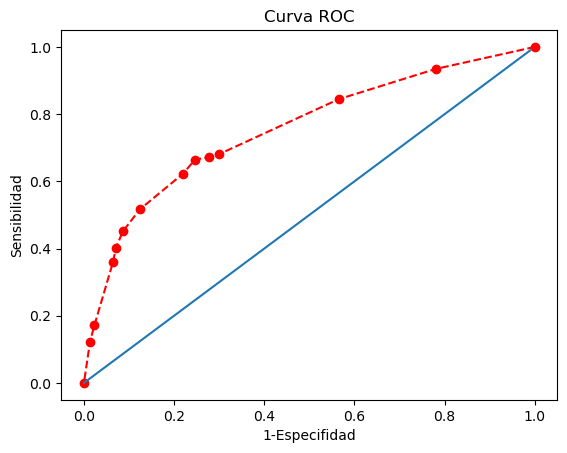

In [83]:
%matplotlib inline
plt.plot(especifities_1, sensitivities, marker="o", linestyle="--", color="r")
x=[i*0.01 for i in range(100)]
y=[i*0.01 for i in range(100)]
plt.plot(x,y)
plt.xlabel("1-Especifidad")
plt.ylabel("Sensibilidad")
plt.title("Curva ROC")

In [87]:
from sklearn import metrics
from plotnine import *

In [91]:
espc_1, sensit, _ = metrics.roc_curve(Y_test, prob)

In [92]:
df = pd.DataFrame({
    "x":espc_1,
    "y":sensit
})

In [93]:
df.head()

,x,y
0,0.000000,0.000000
1,0.000000,0.008197
2,0.000000,0.024590
3,0.000000,0.032787
4,0.002693,0.032787


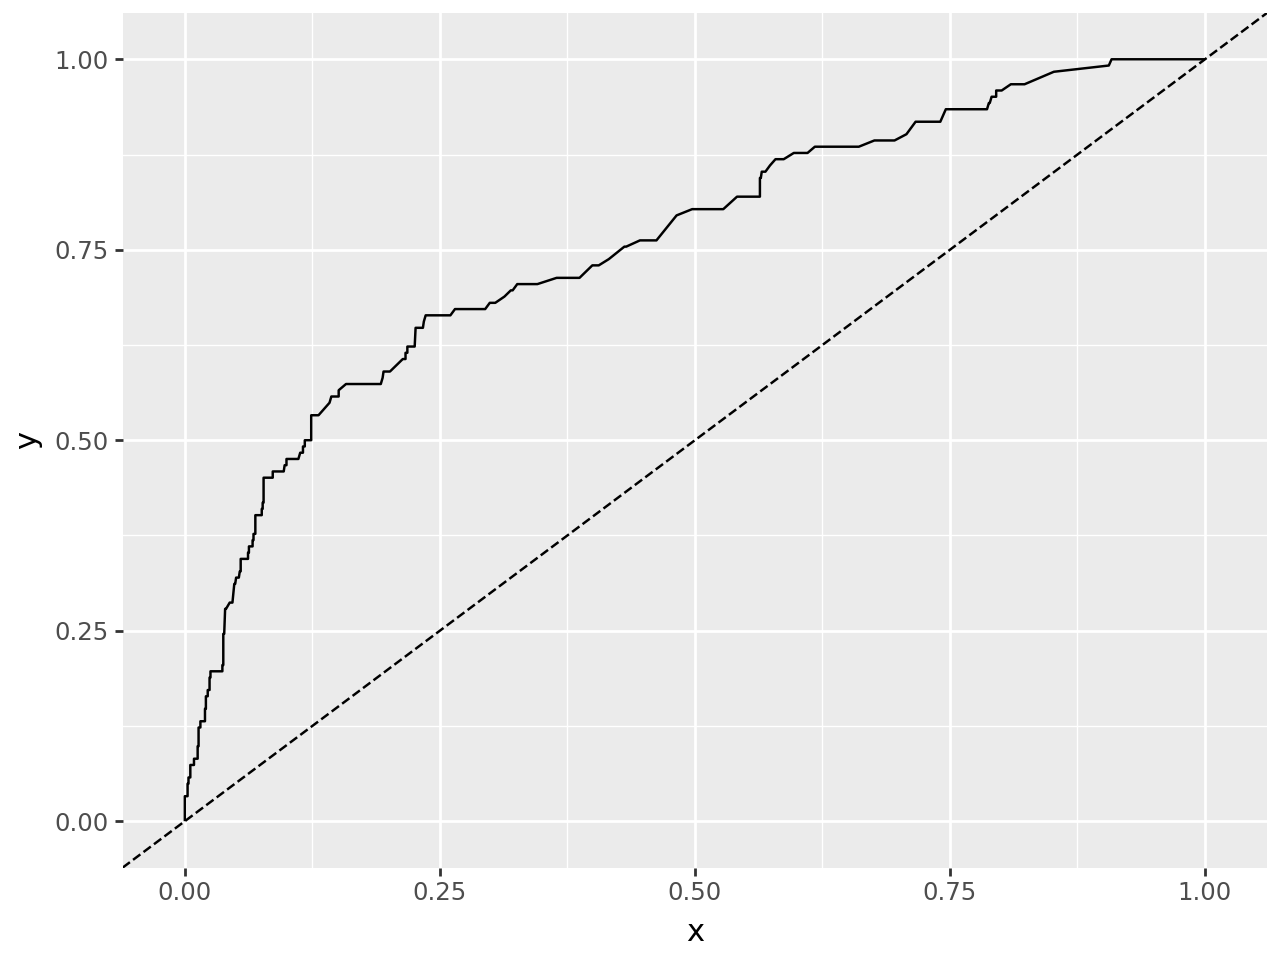

In [101]:
ggplot(df, aes(x="x", y="y")) + geom_line() + geom_abline(linetype="dashed") + xlim(-0.01,1.01) + ylim(-0.01,1.01)

In [96]:
auc = metrics.auc(espc_1, sensit)
auc

0.757850899137652

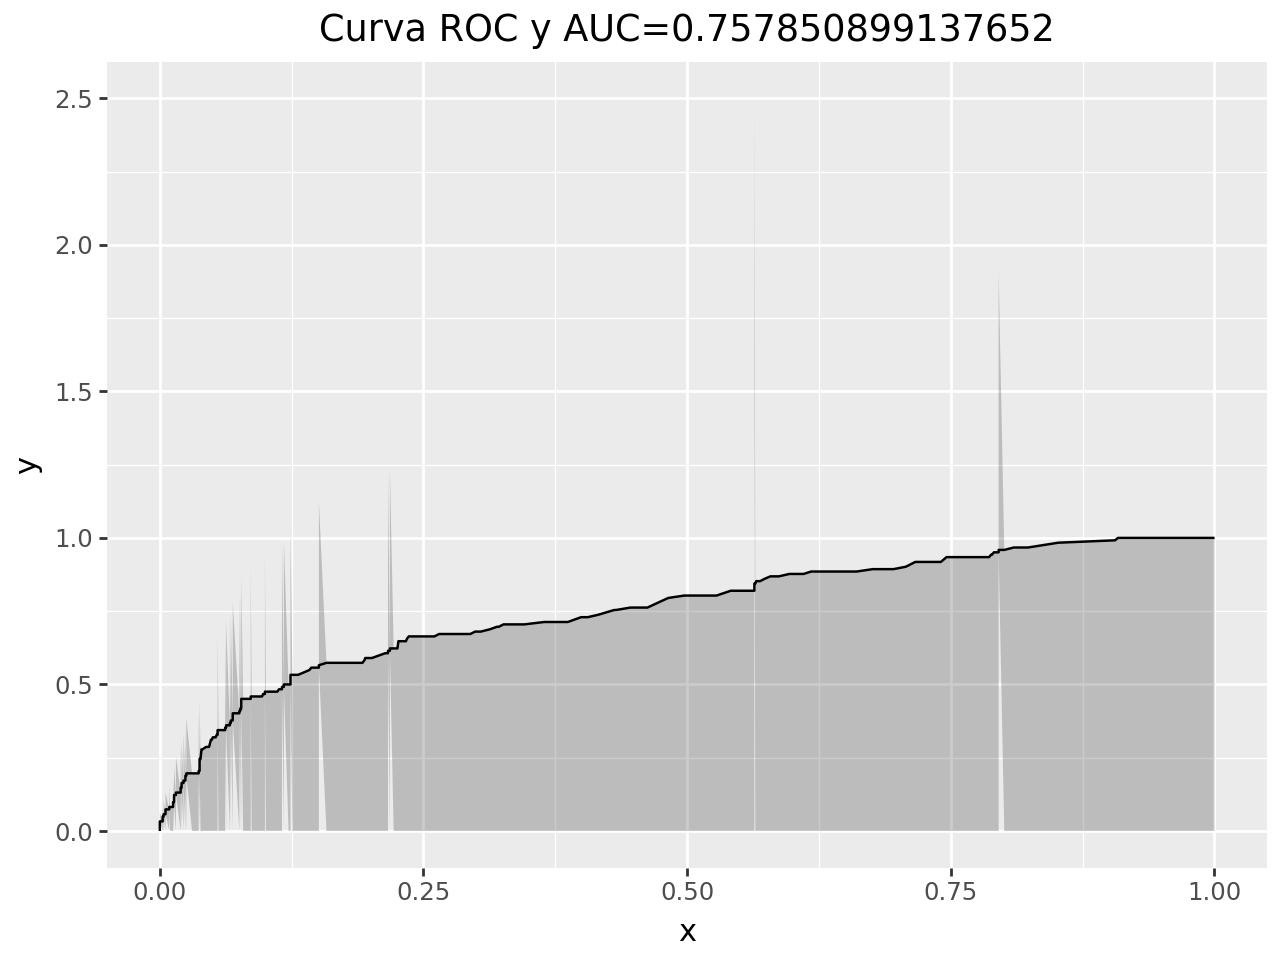

In [100]:
ggplot(df, aes(x="x", y="y")) + geom_area(alpha=0.25) + geom_line(aes(y="y")) + ggtitle("Curva ROC y AUC=%s" % str(auc))